In [1]:
# Import data handling libraries
import pandas as pd
import numpy as np
import os

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, 
    classification_report, 
    confusion_matrix,
    mean_squared_error, 
    r2_score
)

# Import other useful libraries
from pathlib import Path
import joblib
import warnings

# Set plotting style and size
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

# Ignore warnings for cleaner output
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

In [2]:
# Define file paths for the four standardized datasets
forward_ac_path = "forward_AC.csv"
forward_cb_path = "forward_CB.csv"
backward_ca_path = "backward_CA.csv"
backward_bc_path = "backward_BC.csv"

# Read all four datasets
forward_ac_df = pd.read_csv(forward_ac_path)
forward_cb_df = pd.read_csv(forward_cb_path)
backward_ca_df = pd.read_csv(backward_ca_path)
backward_bc_df = pd.read_csv(backward_bc_path)

# Create a dictionary to store all datasets for easier iteration
pathway_dfs = {
    "forward_AC": forward_ac_df,
    "forward_CB": forward_cb_df,
    "backward_CA": backward_ca_df,
    "backward_BC": backward_bc_df
}


In [3]:
def split_the_data(dataset):
    # Two-way split with GridSearchCV 
    # Split data into training and test sets
    X = dataset[['Time', 'Pressure']]
    y = dataset['Mechanism']
    
    # Single split: 80% train, 20% test
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
    
    # Scale the features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Verify the shapes
    print("Data shapes:")
    print(f"Original data: {X.shape[0]} samples")
    print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/X.shape[0]:.1%})")
    print(f"Test set: {X_test.shape[0]} samples ({X_test.shape[0]/X.shape[0]:.1%})")
    
    # Check class distribution
    print("\nClass distribution:")
    print(f"Original: {y.value_counts(normalize=True)}")
    print(f"Train: {y_train.value_counts(normalize=True)}")
    print(f"Test: {y_test.value_counts(normalize=True)}")
    return X_train_scaled, X_test_scaled, y_train, y_test, scaler

In [4]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
def train_the_model(X_train_scaled, X_test_scaled, y_train, y_test, scaler, name):
    param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10]
    }
    
    # GridSearchCV with 5-fold cross-validation
    grid_search = GridSearchCV(
        RandomForestClassifier(random_state=42),
        param_grid,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )
    
    # Fit the grid search
    grid_search.fit(X_train_scaled, y_train)
    best_model = grid_search.best_estimator_
    
    # Print results
    print(f"Best parameters: {grid_search.best_params_}")
    print(f"Cross-validation accuracy: {grid_search.best_score_:.4f}")
    
    # Final evaluation on test set
    y_pred_test = best_model.predict(X_test_scaled)
    test_accuracy = accuracy_score(y_test, y_pred_test)
    print(f"Test accuracy: {test_accuracy:.4f}")

    import joblib

    # Save model and scaler
    joblib.dump(best_model, f"classifier/{name}_classifier.pkl")
    joblib.dump(scaler, f"classifier/{name}_scaler.pkl")
    print("Model and scaler saved")

    return y_test, y_pred_test, best_model

In [5]:
from sklearn.metrics import classification_report

def show_matrix(y_test, y_pred_test, best_model):
    # Create confusion matrix
    cm = confusion_matrix(y_test, y_pred_test)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()
    print(classification_report(y_test, y_pred_test))    

    # Check feature importance
    feature_importance = pd.DataFrame({
        'Feature': ['Time', 'Pressure'],
        'Importance': best_model.feature_importances_
    }).sort_values('Importance', ascending=False)
    
    plt.figure(figsize=(8, 6))
    sns.barplot(x='Importance', y='Feature', data=feature_importance)
    plt.title('Feature Importance')
    plt.tight_layout()
    plt.show()
    


Data shapes:
Original data: 424 samples
Training set: 360 samples (84.9%)
Test set: 64 samples (15.1%)

Class distribution:
Original: Mechanism
0    0.603774
1    0.396226
Name: proportion, dtype: float64
Train: Mechanism
0    0.605556
1    0.394444
Name: proportion, dtype: float64
Test: Mechanism
0    0.59375
1    0.40625
Name: proportion, dtype: float64
Best parameters: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 100}
Cross-validation accuracy: 0.9472
Test accuracy: 0.9219
Model and scaler saved


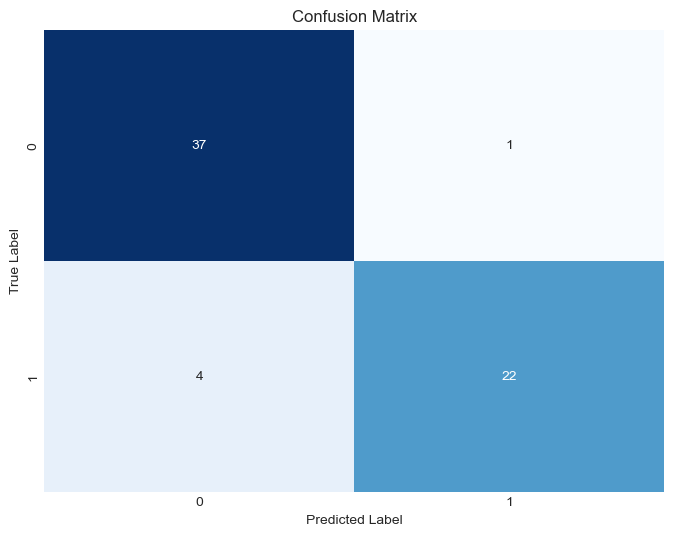

              precision    recall  f1-score   support

           0       0.90      0.97      0.94        38
           1       0.96      0.85      0.90        26

    accuracy                           0.92        64
   macro avg       0.93      0.91      0.92        64
weighted avg       0.92      0.92      0.92        64



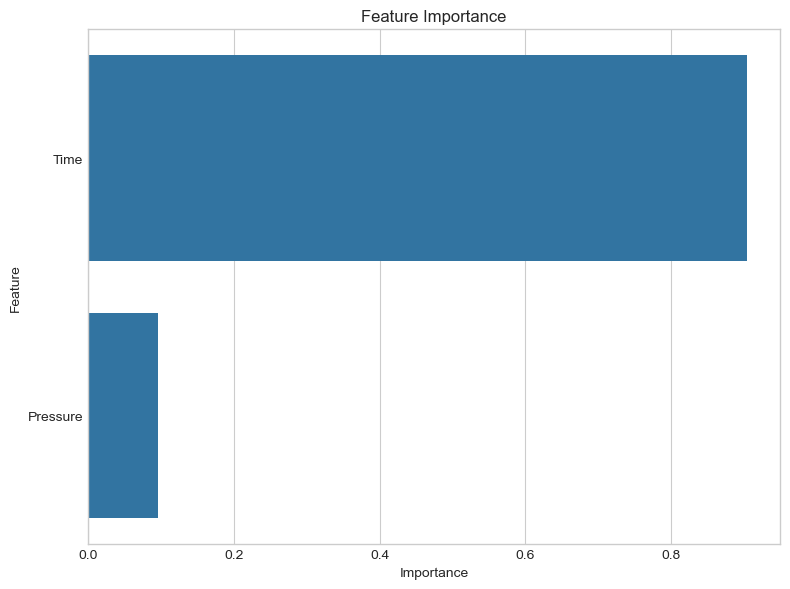

Data shapes:
Original data: 424 samples
Training set: 360 samples (84.9%)
Test set: 64 samples (15.1%)

Class distribution:
Original: Mechanism
0    0.610849
1    0.389151
Name: proportion, dtype: float64
Train: Mechanism
0    0.630556
1    0.369444
Name: proportion, dtype: float64
Test: Mechanism
1    0.5
0    0.5
Name: proportion, dtype: float64
Best parameters: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 50}
Cross-validation accuracy: 0.9056
Test accuracy: 0.8438
Model and scaler saved


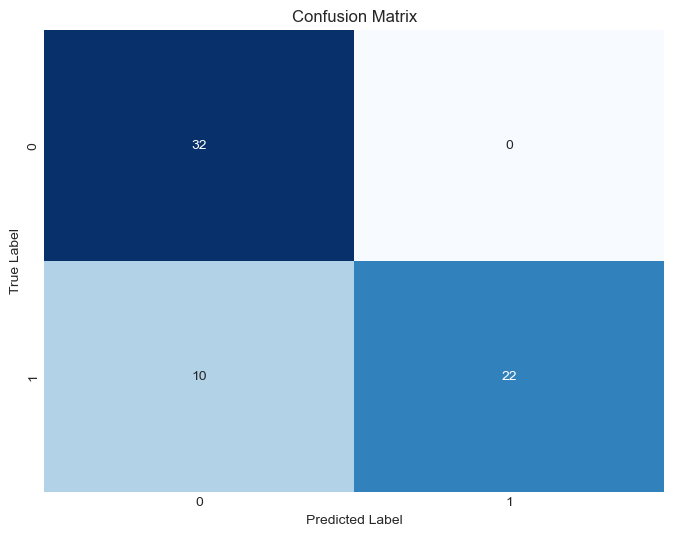

              precision    recall  f1-score   support

           0       0.76      1.00      0.86        32
           1       1.00      0.69      0.81        32

    accuracy                           0.84        64
   macro avg       0.88      0.84      0.84        64
weighted avg       0.88      0.84      0.84        64



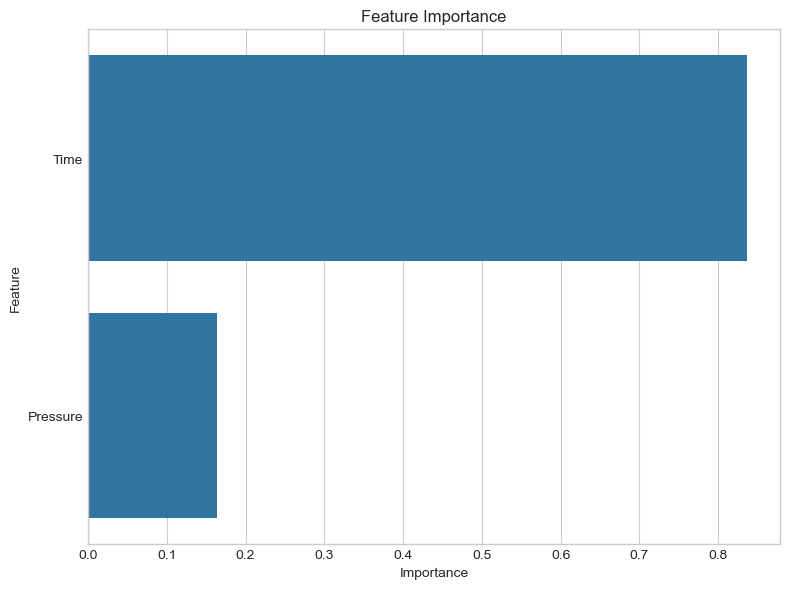

Data shapes:
Original data: 421 samples
Training set: 357 samples (84.8%)
Test set: 64 samples (15.2%)

Class distribution:
Original: Mechanism
0    0.603325
1    0.396675
Name: proportion, dtype: float64
Train: Mechanism
0    0.613445
1    0.386555
Name: proportion, dtype: float64
Test: Mechanism
0    0.546875
1    0.453125
Name: proportion, dtype: float64
Best parameters: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 50}
Cross-validation accuracy: 0.9551
Test accuracy: 0.8438
Model and scaler saved


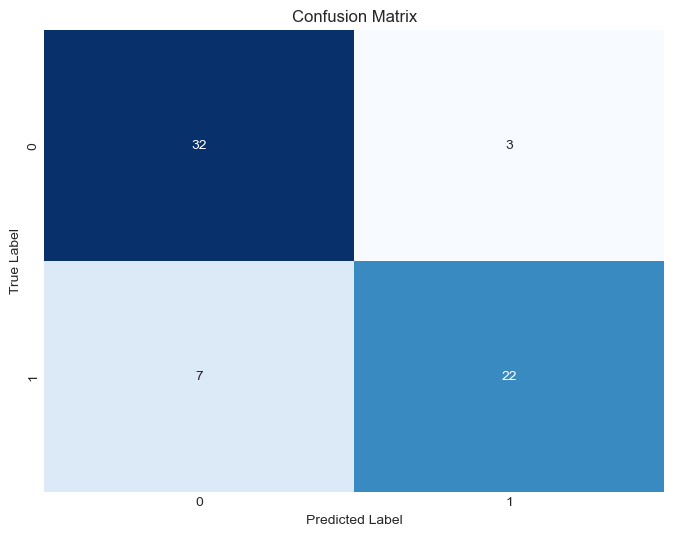

              precision    recall  f1-score   support

           0       0.82      0.91      0.86        35
           1       0.88      0.76      0.81        29

    accuracy                           0.84        64
   macro avg       0.85      0.84      0.84        64
weighted avg       0.85      0.84      0.84        64



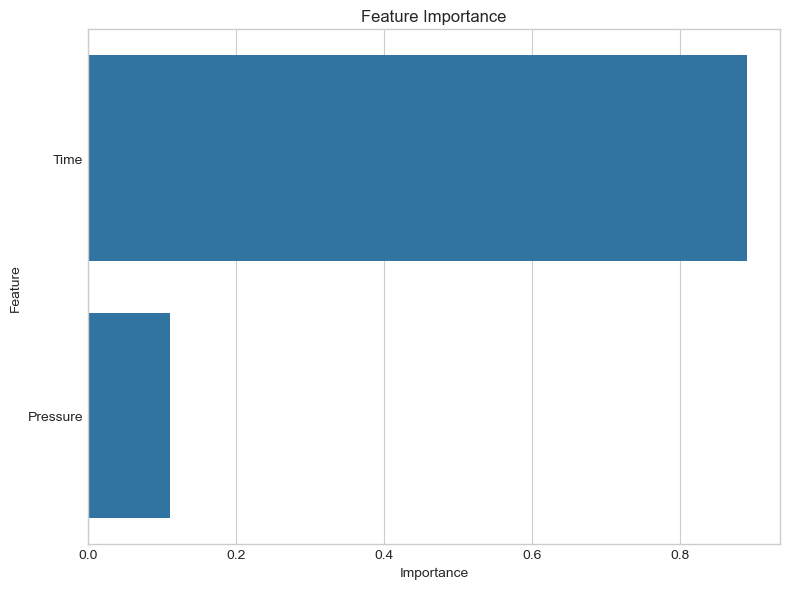

Data shapes:
Original data: 421 samples
Training set: 357 samples (84.8%)
Test set: 64 samples (15.2%)

Class distribution:
Original: Mechanism
0       0.619952
1       0.377672
4035    0.002375
Name: proportion, dtype: float64
Train: Mechanism
0       0.635854
1       0.361345
4035    0.002801
Name: proportion, dtype: float64
Test: Mechanism
0    0.53125
1    0.46875
Name: proportion, dtype: float64
Best parameters: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}
Cross-validation accuracy: 0.9299
Test accuracy: 0.9062
Model and scaler saved


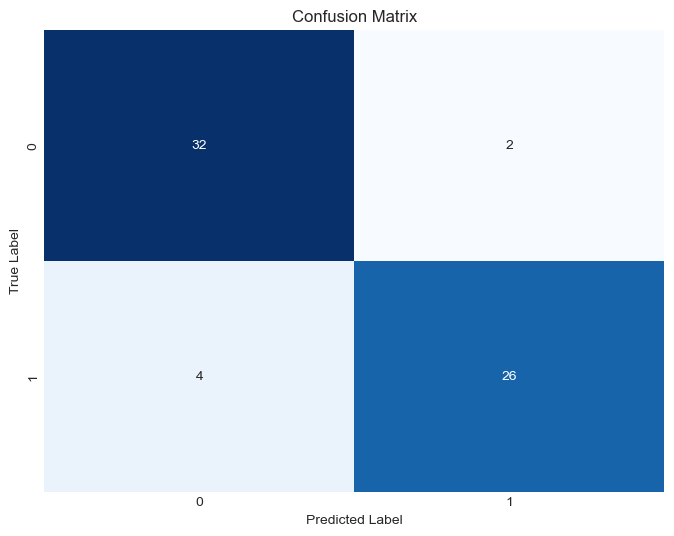

              precision    recall  f1-score   support

           0       0.89      0.94      0.91        34
           1       0.93      0.87      0.90        30

    accuracy                           0.91        64
   macro avg       0.91      0.90      0.91        64
weighted avg       0.91      0.91      0.91        64



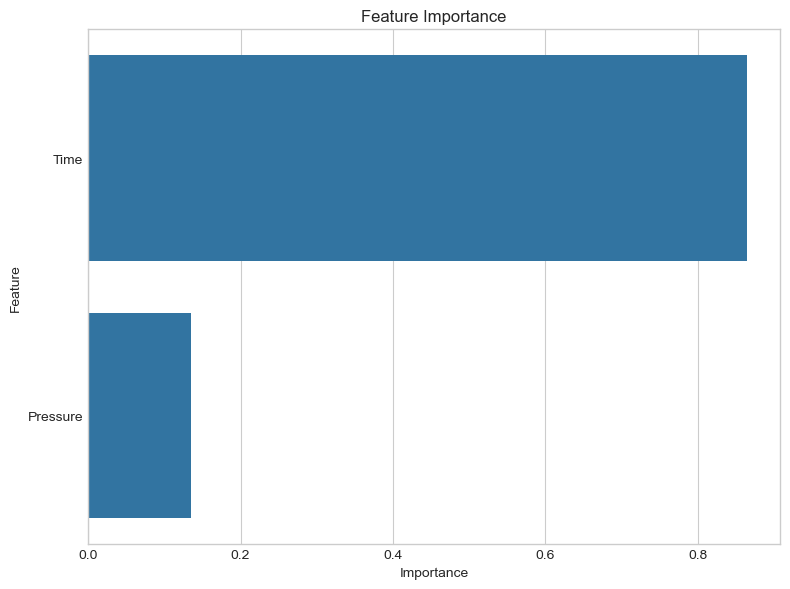

In [7]:
for data_name, dataset in pathway_dfs.items():
    X_train_scaled, X_test_scaled, y_train, y_test, scaler = split_the_data(dataset)
    y_test, y_pred_test, best_model = train_the_model(X_train_scaled, X_test_scaled, y_train, y_test, scaler, data_name)
    show_matrix(y_test, y_pred_test, best_model)

In [8]:
def split_the_data_reg(dataset):
    # Define features and target for pressure prediction
    X_pressure = dataset[['Time', 'Mechanism']]
    y_pressure = dataset['Pressure']
    
    # Split data
    X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
        X_pressure, y_pressure, test_size=0.15, random_state=42
    )
    
    # Scale features
    scaler_p = StandardScaler()
    X_train_p_scaled = scaler_p.fit_transform(X_train_p)
    X_test_p_scaled = scaler_p.transform(X_test_p)
    return X_train_p_scaled, X_test_p_scaled, y_train_p, y_test_p, scaler

In [9]:
def train_reg_model(X_train_p_scaled, X_test_p_scaled, y_train_p, y_test_p, scaler, name):
    # Define parameter grid for regressor
    param_grid_reg = {
        'n_estimators': [50, 100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5, 10]
    }
    
    # Grid search
    grid_search_reg = GridSearchCV(
        RandomForestRegressor(random_state=42),
        param_grid_reg,
        cv=5,
        scoring='neg_mean_squared_error',
        n_jobs=-1
    )
    
    grid_search_reg.fit(X_train_p_scaled, y_train_p)
    best_pressure_model = grid_search_reg.best_estimator_
    
    # Test predictions
    y_pred_p = best_pressure_model.predict(X_test_p_scaled)
    mse = mean_squared_error(y_test_p, y_pred_p)
    r2 = r2_score(y_test_p, y_pred_p)
    
    print(f"Best pressure model parameters: {grid_search_reg.best_params_}")
    print(f"Mean Squared Error: {mse:.4f}")
    print(f"R² Score: {r2:.4f}")
    import joblib

    # Save model and scaler
    joblib.dump(best_model, f"regressor/{name}_classifier.pkl")
    joblib.dump(scaler, f"regressor/{name}_scaler.pkl")
    print("Model and scaler saved")
    return y_test_p, y_pred_p

In [10]:
def plot_reg(y_test_p, y_pred_p):
    # Plot actual vs predicted values
    plt.figure(figsize=(10, 6))
    plt.scatter(y_test_p, y_pred_p, alpha=0.5)
    plt.plot([min(y_test_p), max(y_test_p)], [min(y_test_p), max(y_test_p)], 'r--')
    plt.xlabel('Actual Pressure')
    plt.ylabel('Predicted Pressure')
    plt.title('Actual vs Predicted Pressure Values')
    plt.grid(True)
    plt.show()

Best pressure model parameters: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 50}
Mean Squared Error: 0.1732
R² Score: 0.8168
Model and scaler saved


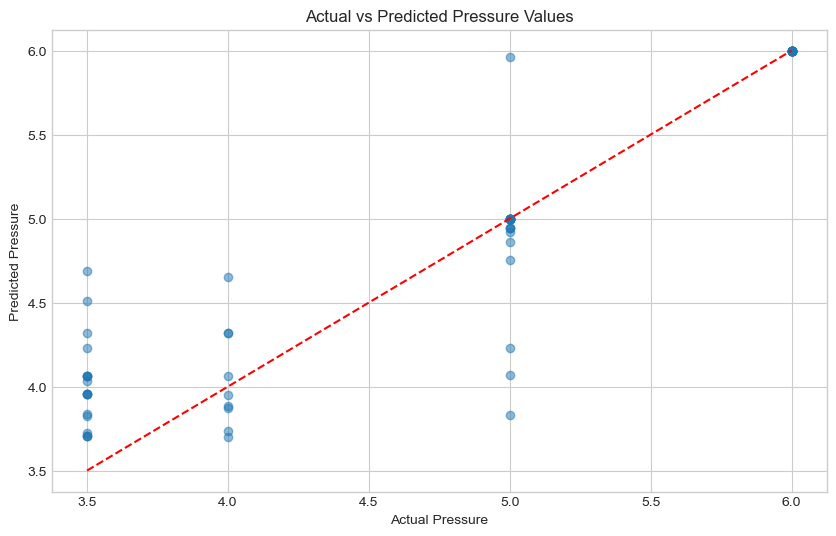

Best pressure model parameters: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 50}
Mean Squared Error: 0.2035
R² Score: 0.7848
Model and scaler saved


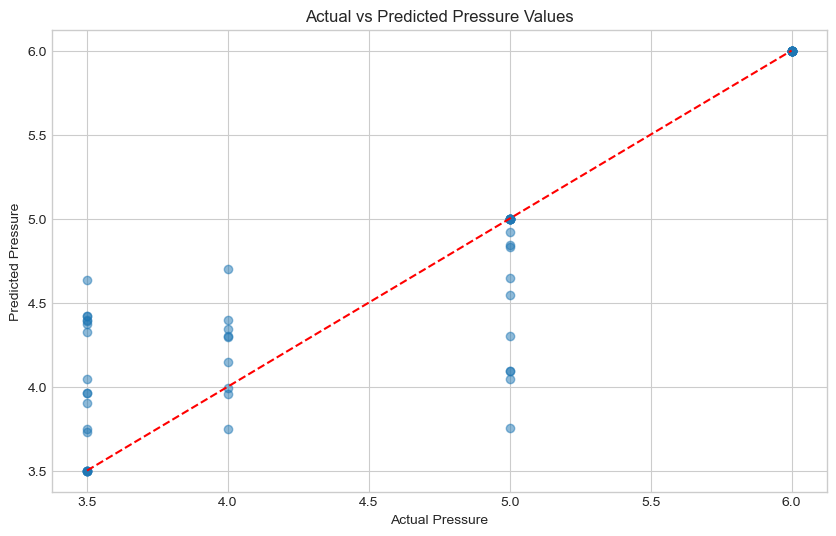

Best pressure model parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Mean Squared Error: 0.2170
R² Score: 0.7766
Model and scaler saved


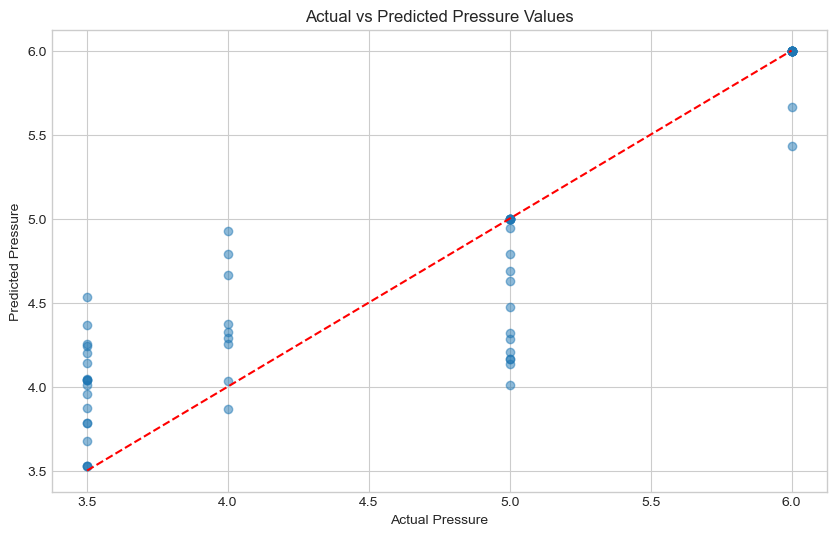

Best pressure model parameters: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 50}
Mean Squared Error: 0.0772
R² Score: 0.9205
Model and scaler saved


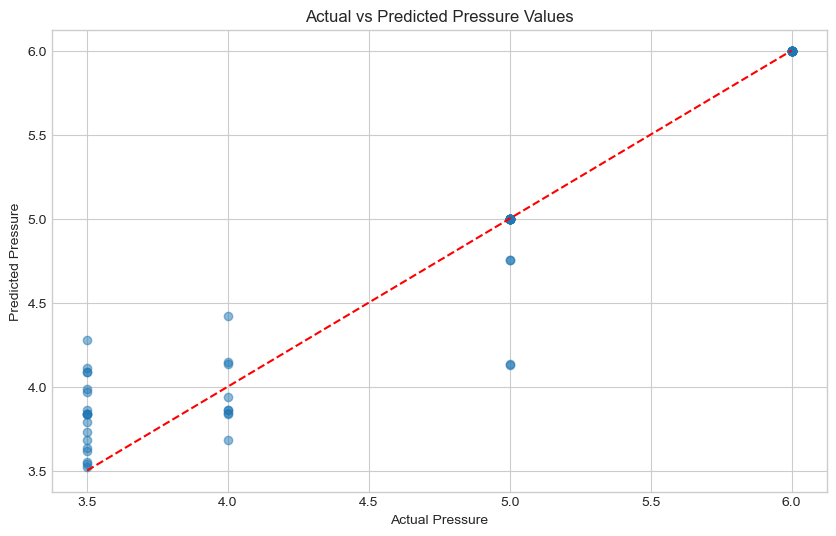

In [11]:
for data_name, dataset in pathway_dfs.items():
    X_train_p_scaled, X_test_p_scaled, y_train_p, y_test_p, scaler = split_the_data_reg(dataset)
    y_test_p, y_pred_p = train_reg_model(X_train_p_scaled, X_test_p_scaled, y_train_p, y_test_p, scaler, data_name)
    plot_reg(y_test_p, y_pred_p)

In [ ]:
import joblib
import pandas as pd

# Example: use the saved forward_AC classifier on new data.
# Run the training cells above first; they save the models to classifier/.

# Step 1: Load new data (here: the first 10 rows of forward_AC.csv as an example)
df = pd.read_csv('forward_AC.csv')[['Time', 'Pressure']].head(10)

# Step 2: Load scaler and classifier (saved with joblib by the training cells)
scaler = joblib.load('classifier/forward_AC_scaler.pkl')
classifier = joblib.load('classifier/forward_AC_classifier.pkl')

# Step 3: Scale input
scaled_input = scaler.transform(df)

# Step 4: Predict (probability or label)
predictions_proba = classifier.predict_proba(scaled_input)
predictions = classifier.predict(scaled_input)

# Step 5: Show results
result_df = pd.DataFrame(predictions_proba, columns=classifier.classes_)
result_df['predicted_label'] = predictions
print(result_df)
